# Лабораторная работа № 6.  Генеративно-состязательные сети (GAN)

## ( “Нейросетевые технологии обработки данных”)

### студентки 4-го курса 10-ой группы

### Ярмош Алеси

### Вариант 13

Кольцо из 7 гауссиан,
R = 3.2
x = (3.2 cos αk, 3.2 sin αk) + ε, αk = 2πk / 7, k ∈{0..6}, ε ∼ N (0, 0.13^2I)

## Постановка задачи

Реализовать на PyTorch простую GAN (генератор и дискриминатор – МСП) для генерации точек, распределённых по заданному 2D-закону из своего варианта.

Отчёт должен содержать:

1. Формулу генерации целевого распределения и визуализацию обучающей выборки
(например, 1000–2000 точек).

2. Структурные схемы генератора и дискриминатора (число слоёв, нейронов, функции
активации, оптимизатор, скорости обучения, число эпох) с кратким обоснованием
выбора.

3. Графики кривых потерь LD и LG по эпохам на одних осях.

4. Визуализацию сгенерированных точек (наложенных на реальные) минимум на 3 разных эпохах обучения, демонстрирующую сходимость облака к целевой форме.

5. Обсуждение: наблюдался ли коллапс мод (если распределение многомодально) или
иные проблемы обучения; что помогло/помешало устойчивому обучению.

**Импорт библиотек.** NumPy — для генерации выборки, PyTorch (`torch`, `torch.nn`) — для генератора, дискриминатора и обучения.

In [1]:
import numpy as np
import torch.nn as nn
import torch

**Фиксация случайного зерна** для воспроизводимости: выборка и инициализация весов будут одинаковыми при каждом запуске.

In [2]:
torch.manual_seed(42)
np.random.seed(42)

**Параметры целевого распределения.** `R = 3.2` — радиус кольца, `N_DOTS = 1000` — число точек в обучающей выборке.

In [3]:
R = 3.2
N_DOTS = 1000

**Генерация обучающей выборки (кольцо из 7 гауссиан).** Реализация формулы варианта: для каждой точки случайно выбирается одна из 7 мод k ∈ {0..6}, её центр лежит на угле αk = 2πk/7 на окружности радиуса R, и вокруг центра добавляется гауссов шум N(0, 0.13²). На выходе — массив (n, 2).

In [4]:
def sample_ring(n):
    k = np.random.randint(0, 7, size=n)
    alpha = 2 * np.pi * k / 7
    centers = np.stack([np.cos(alpha), np.sin(alpha)], axis=1) * R
    noise = np.random.randn(n, 2) * 0.13
    return (centers + noise).astype(np.float32)

**Визуализация обучающей выборки.** 

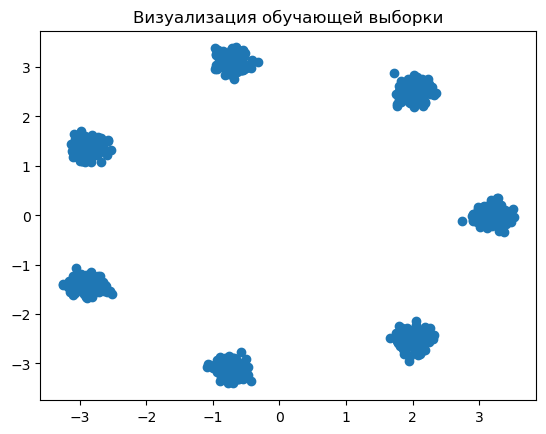

In [5]:
import matplotlib.pyplot as plt
X = sample_ring(N_DOTS)
plt.scatter(X[:, 0], X[:, 1])
plt.title('Визуализация обучающей выборки')
plt.show()

**Размерность латентного пространства.** `Z_DIM = 2` — длина вектора случайного шума z, из которого генератор делает точку.

In [6]:
Z_DIM = 2

**Архитектуры генератора и дискриминатора (пункт 2 отчёта).**
- **Генератор:** из шума z (2 числа) через скрытые слои с ReLU получает точку (2 числа).
- **Дискриминатор:** из точки (2 числа) через скрытые слои с LeakyReLU(0.2) выдаёт один логит — оценку «настоящая/поддельная». LeakyReLU важен, чтобы градиент не обнулялся на отрицательной стороне (проблема «мёртвых» нейронов) — через дискриминатор градиент идёт и к генератору.

In [7]:
class Generator(nn.Module):
    def __init__(self, z_dim=Z_DIM, hidden=128, n_hidden=1):
        super().__init__()

        layers = [nn.Linear(z_dim, hidden), nn.ReLU()]

        for _ in range(n_hidden):
            layers.append(nn.Linear(hidden, hidden))
            layers.append(nn.ReLU())

        layers.append(nn.Linear(hidden, z_dim))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

class Discriminator(nn.Module):
    def __init__(self, z_dim=Z_DIM, hidden=128, n_hidden=1):
        super().__init__()

        layers = [nn.Linear(z_dim, hidden), nn.LeakyReLU(0.2)]

        for _ in range(n_hidden):
            layers.append(nn.Linear(hidden, hidden))
            layers.append(nn.LeakyReLU(0.2))

        layers.append(nn.Linear(hidden, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

**Структурная схема генератора.** `torchview` рисует граф сети G: вход — вектор шума размерности Z_DIM.

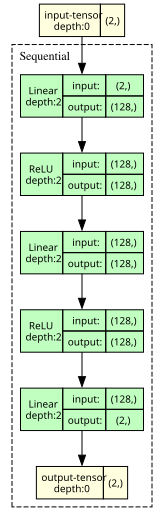

In [8]:
G = Generator()

from torchview import draw_graph
model_G = draw_graph(
    G,
    input_size=((Z_DIM,)),  # batch, channels, height, width
    graph_name="SimpleCNN",
    expand_nested=True
)
model_G.visual_graph

**Структурная схема дискриминатора.** Граф сети D: вход — точка размерности Z_DIM, выход — один логит.

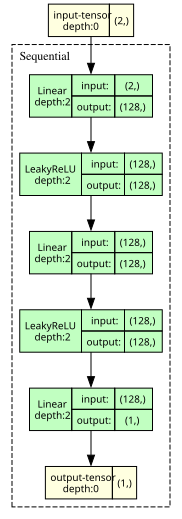

In [9]:
D = Discriminator()

model_D = draw_graph(
    D,
    input_size=((Z_DIM,)),
    graph_name="SimpleCNN",
    expand_nested=True
)
model_D.visual_graph

**Оптимизаторы и функция потерь.** Отдельные Adam для G и D (lr=1e-3, β=(0.5, 0.999) — стандарт для GAN). `BCEWithLogitsLoss` — бинарная кросс-энтропия, принимающая сырые логиты (сигмоида встроена внутрь, численно устойчивее).

In [10]:
optG = torch.optim.Adam(params=G.parameters(), lr=1e-3, betas=(0.5, 0.999))
optD = torch.optim.Adam(params=D.parameters(), lr=1e-3, betas=(0.5, 0.999))
bce = nn.BCEWithLogitsLoss()

**Гиперпараметры обучения.** `N_EPOCHS = 4000` — число эпох; `D_STEPS = 1` — сколько шагов дискриминатора на один шаг генератора.

In [11]:
N_EPOCHS = 4000
D_STEPS = 1

**Функция обучения GAN.** Две сети учатся попеременно мини-батчами:
- **Шаг дискриминатора:** на реальных точках D учат выдавать 1, на поддельных `G(z)` — 0. `.detach()` отрезает подделки от графа генератора, чтобы на этом шаге обновлялся только D.
- **Шаг генератора:** G учат так, чтобы D принял его подделки за настоящие (метка 1) — это non-saturating loss; здесь detach НЕ ставится, градиент должен дойти до G.
Попутно на 4 равномерно выбранных эпохах сохраняются снимки облаков реальных и сгенерированных точек (пункт 4 отчёта).

In [12]:
def train(G=G, D=D, optG=optG, optD=optD, n_epochs=N_EPOCHS, d_steps=D_STEPS):
    BATCH_SIZE = 128

    lossG_hist, lossD_hist = [], []

    fig, axes = plt.subplots(2, 2, figsize=(10, 10))
    ax_iter = iter(axes.flat)

    for epoch in range(1, n_epochs + 1):
        epochG_hist, epochD_hist = [], []
        start = 0
        for finish in range(BATCH_SIZE, N_DOTS, BATCH_SIZE):

            for _ in range(d_steps):
                # Discriminator step
                real = torch.tensor(X[start:finish])
                z = torch.randn(BATCH_SIZE, Z_DIM)
                fake = G(z).detach()
                d_fake, d_real = D(fake), D(real)
                lossD = bce(d_real, torch.ones_like(d_real)) + bce(d_fake, torch.zeros_like(d_fake))
                optD.zero_grad(); lossD.backward(); optD.step()

            # Generator step
            z = torch.randn(BATCH_SIZE, Z_DIM)
            fake = G(z)
            d_fake2 = D(fake)
            lossG = bce(d_fake2, torch.ones_like(d_fake2))
            optG.zero_grad(); lossG.backward(); optG.step()

            epochG_hist.append(lossG.item()); epochD_hist.append(lossD.item())

        start = finish
        lossG_hist.append(np.mean(epochG_hist))
        lossD_hist.append(np.mean(epochD_hist))

        snapshots = list(np.linspace(1, n_epochs, 4, dtype=int))
        if epoch in snapshots:
            ax = next(ax_iter)
            ax.scatter(real[:, 0].numpy(), real[:, 1].numpy(), label='real')
            ax.scatter(fake[:, 0].detach().numpy(), fake[:, 1].detach().numpy(), label='fake')
            ax.legend()

    plt.show()
    return (lossG_hist, lossD_hist)

**Запуск обучения.** Возвращает истории потерь генератора и дискриминатора по эпохам.

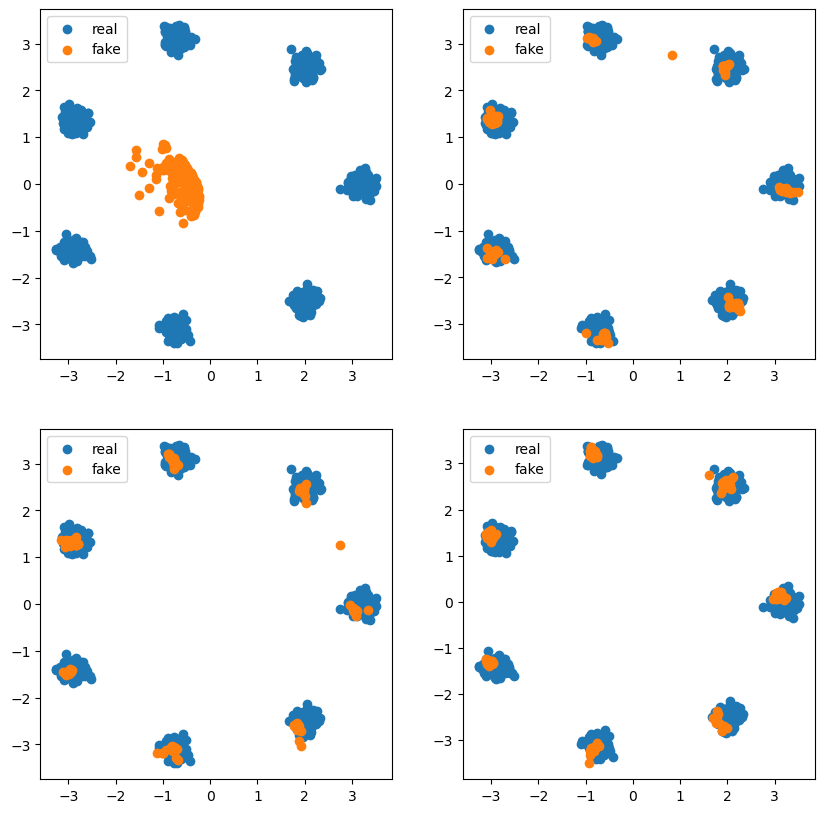

In [13]:
lossG_hist, lossD_hist = train()

**Кривые потерь L_D и L_G на одних осях (пункт 3 отчёта).** В отличие от обычной сети, эти кривые не обязаны монотонно падать — при здоровом обучении они колеблются вокруг равновесия двух конкурирующих сетей.

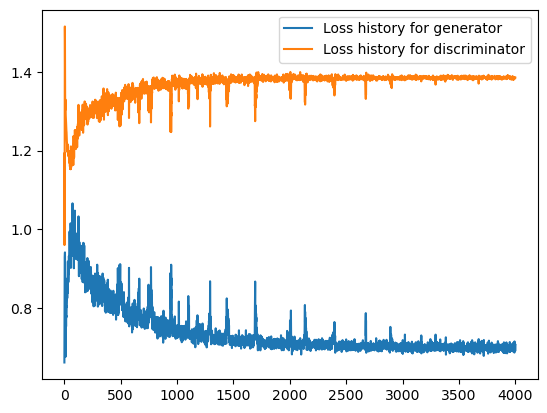

In [14]:
plt.plot(range(1, N_EPOCHS + 1), lossG_hist, label='Loss history for generator')
plt.plot(range(1, N_EPOCHS + 1), lossD_hist, label='Loss history for discriminator')
plt.legend()
plt.show()

Дополнительное задание повышенной сложности (на 10 баллов)

Продемонстрируйте на своём варианте (или на дополнительном многомодальном распределении, например варианте 1, 2, 3 или 6) преднамеренный коллапс мод: подберите гиперпараметры (например, число шагов дискриминатора k на один шаг генератора,
соотношение скоростей обучения ηD/ηG, относительную ёмкость сетей), при которых генератор перестаёт покрывать все моды целевого распределения. Постройте график доли
точек, приходящихся на каждую моду, до и после «порчи» гиперпараметров, и объясните,
почему выбранное изменение гиперпараметров привело к коллапсу мод.

**Метрики покрытия мод (для доп-задания).**
- `mode_stats` — генерирует точки и считает, какая доля попала в окрестность каждой из 7 мод (по ближайшему центру).
- `coverage_score` — сколько мод реально покрыто (доля ≥ 1%) и энтропия распределения по модам: чем она ниже, тем сильнее коллапс (генератор свалился в несколько мод).

In [15]:
k_idx = np.arange(7)
CENTERS = np.stack([np.cos(2*np.pi*k_idx/7), np.sin(2*np.pi*k_idx/7)], axis=0).T * R  # (7,2)

@torch.no_grad()
def mode_stats(G, n=2000):
    z = torch.randn(n, Z_DIM)
    fake = G(z).numpy()
    d = np.linalg.norm(fake[:, None, :] - CENTERS[None, :, :], axis=2)  # (n,7)
    nearest = d.argmin(axis=1)
    counts = np.bincount(nearest, minlength=7) / n   # доля на каждую моду
    return counts

def coverage_score(counts):
    p = counts[counts >= 0.01]
    covered = int((counts >= 0.01).sum())     # сколько мод покрыто
    print(f'Мод покрыто: {covered}')
    return -(p * np.log(p)).sum()   # энтропия распределения по модам

**Подбор гиперпараметров для демонстрации коллапса мод (доп-задание).** Функция-цель для Optuna: перебирает число шагов дискриминатора k, относительную ёмкость и число слоёв сетей, обучает GAN с этими параметрами и возвращает метрику покрытия мод. Минимизация ведёт к набору гиперпараметров, провоцирующему коллапс.

In [16]:
import optuna

def objective(trial):
    k = trial.suggest_categorical('D_steps', [1, 2, 3])
    lr_ratio = trial.suggest_categorical('lr_ratio', [1e-1, 1e-2])
    lr_ratio = 1
    hidden_ratio = trial.suggest_categorical('hidden_ratio', [1, 2])
    G_layers = trial.suggest_categorical('G_layers', [1])
    D_layers = trial.suggest_categorical('D_layers', [1, 2])

    G_hidden = 64
    G = Generator(hidden=G_hidden, n_hidden=G_layers)
    G_lr = 1e-3
    optG = torch.optim.Adam(G.parameters(), G_lr, (0.5, 0.999))

    D_hidden = G_hidden * hidden_ratio
    D = Discriminator(hidden=D_hidden, n_hidden=D_layers)
    D_lr = G_lr / lr_ratio
    optD = torch.optim.Adam(D.parameters(), D_lr, (0.5, 0.999))

    # add n_epochs optimization
    (lossG_hist, lossD_hist) = train(G, D, optG, optD, d_steps=k)

    counts = mode_stats(G)
    score = coverage_score(counts)

    return score

**Запуск оптимизации Optuna** — 10 испытаний с разными наборами гиперпараметров, поиск настроек с наихудшим покрытием мод.

[I 2026-11-04 14:02:31,567] A new study created in memory with name: no-name-1edeac2c-a18e-4c8e-af79-1387d6d4b066


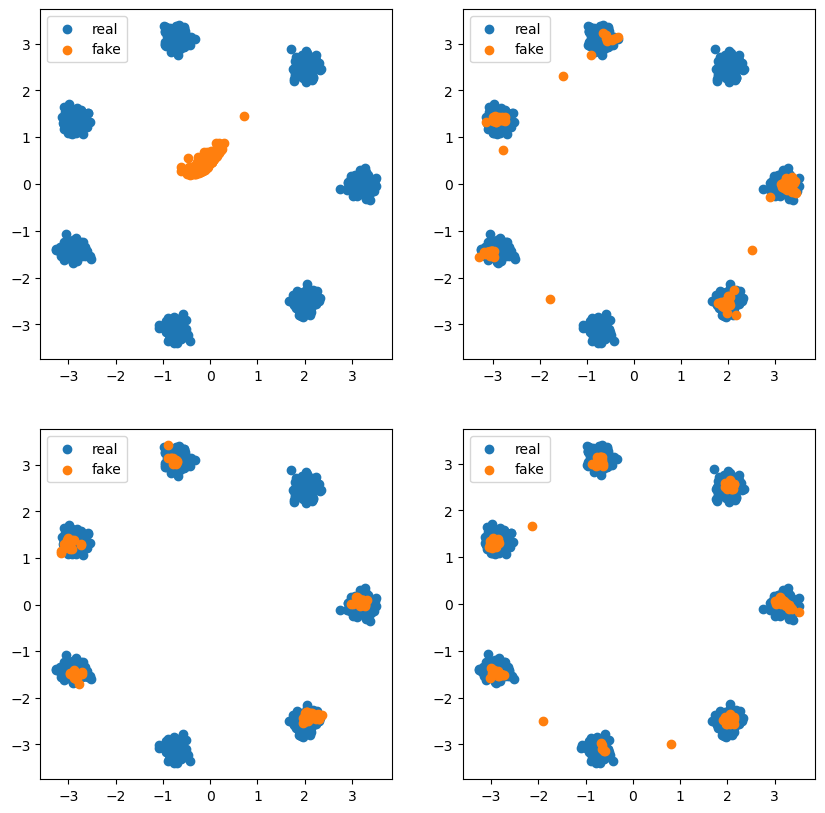

[I 2026-11-04 14:03:31,731] Trial 0 finished with value: 1.8710960337785685 and parameters: {'D_steps': 2, 'lr_ratio': 0.01, 'hidden_ratio': 2, 'G_layers': 1, 'D_layers': 1}. Best is trial 0 with value: 1.8710960337785685.


Мод покрыто: 7


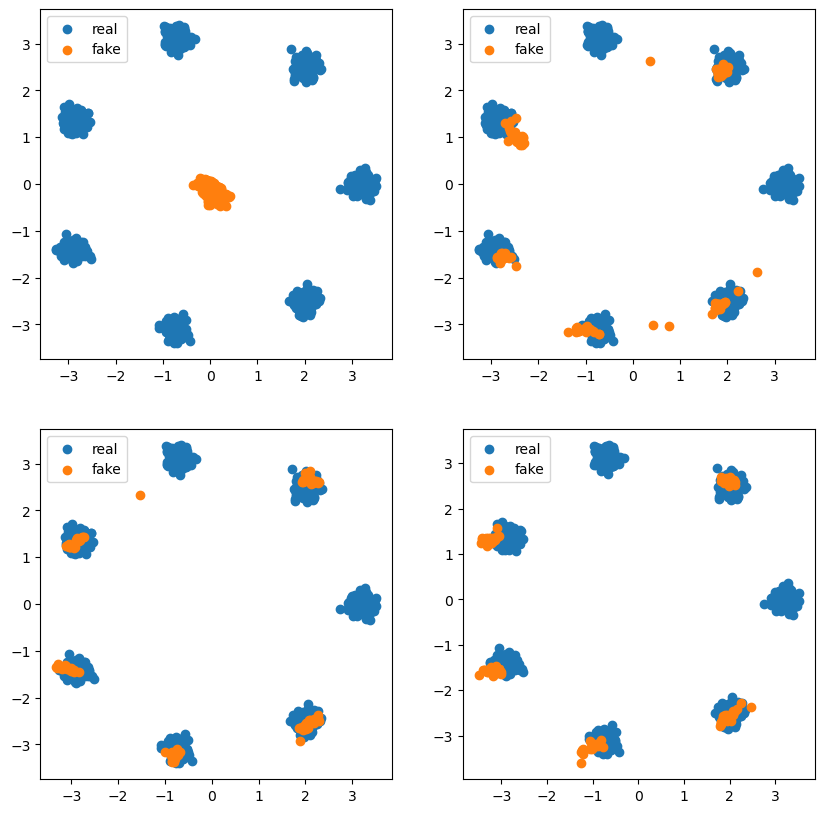

[I 2026-11-04 14:04:48,027] Trial 1 finished with value: 1.5953948557861874 and parameters: {'D_steps': 2, 'lr_ratio': 0.01, 'hidden_ratio': 2, 'G_layers': 1, 'D_layers': 2}. Best is trial 1 with value: 1.5953948557861874.


Мод покрыто: 5


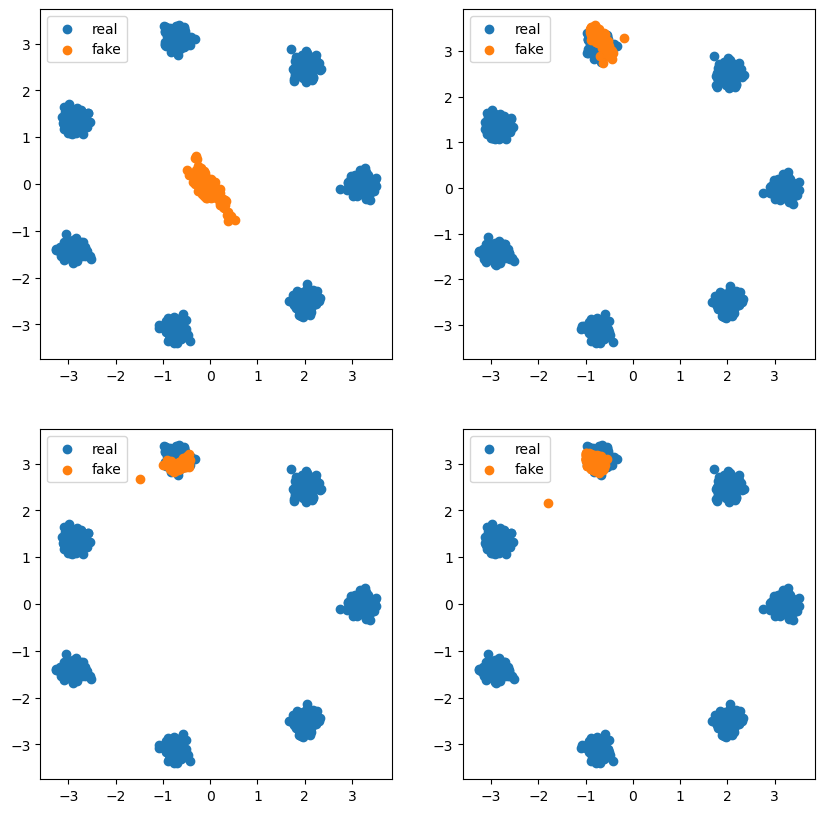

[I 2026-11-04 14:06:36,163] Trial 2 finished with value: 0.002995495493237828 and parameters: {'D_steps': 3, 'lr_ratio': 0.01, 'hidden_ratio': 2, 'G_layers': 1, 'D_layers': 2}. Best is trial 2 with value: 0.002995495493237828.


Мод покрыто: 1


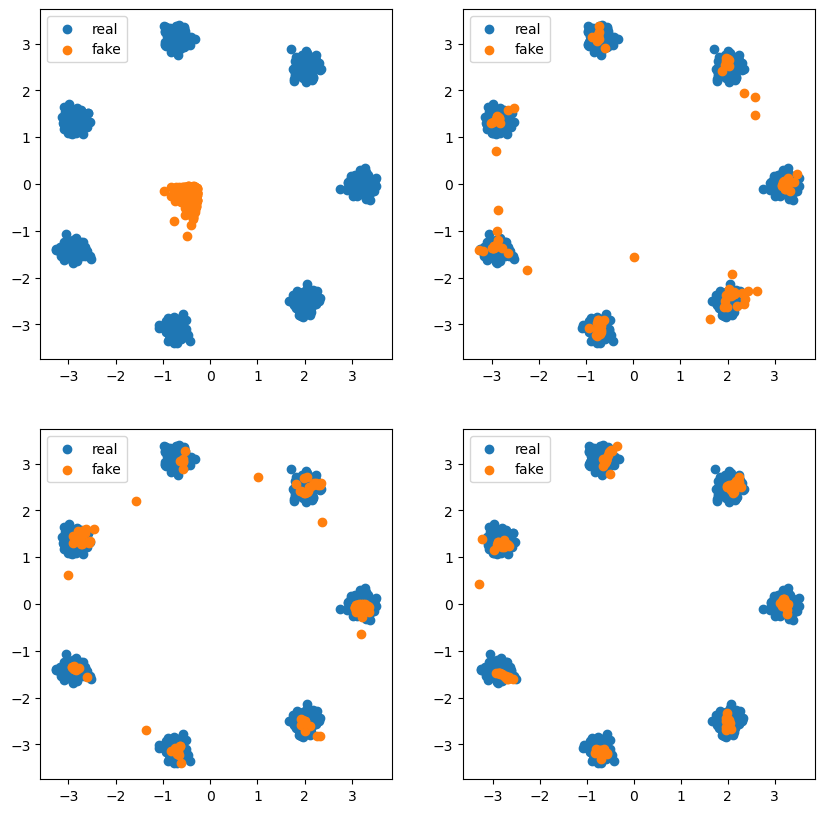

[I 2026-11-04 14:07:12,317] Trial 3 finished with value: 1.9376605179447703 and parameters: {'D_steps': 1, 'lr_ratio': 0.01, 'hidden_ratio': 2, 'G_layers': 1, 'D_layers': 1}. Best is trial 2 with value: 0.002995495493237828.


Мод покрыто: 7


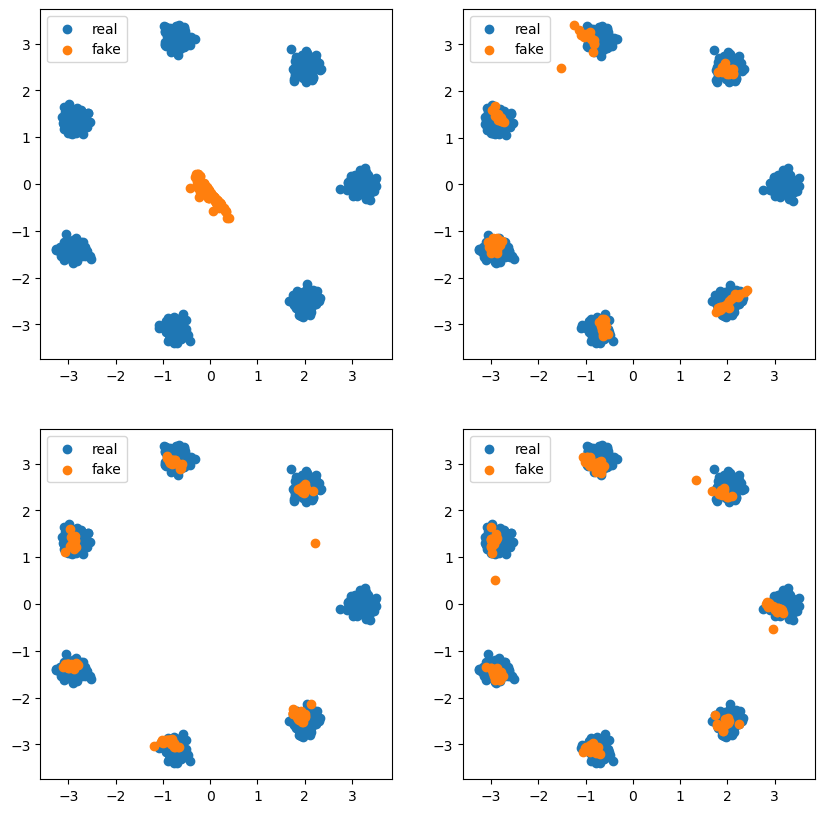

[I 2026-11-04 14:09:06,801] Trial 4 finished with value: 1.922447829244366 and parameters: {'D_steps': 3, 'lr_ratio': 0.1, 'hidden_ratio': 2, 'G_layers': 1, 'D_layers': 2}. Best is trial 2 with value: 0.002995495493237828.


Мод покрыто: 7


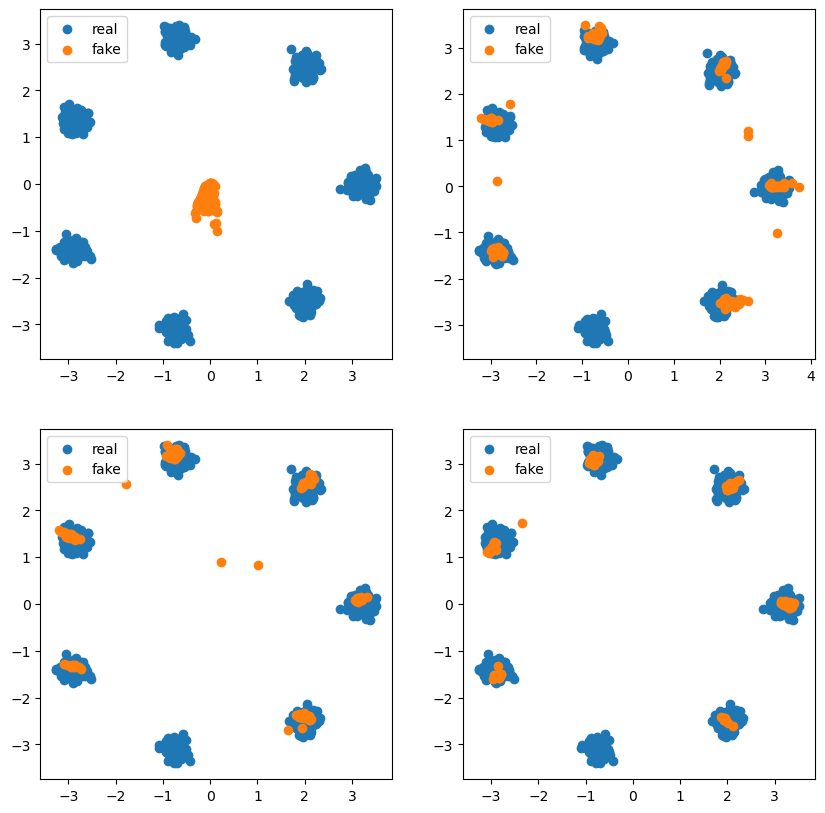

[I 2026-11-04 14:10:04,850] Trial 5 finished with value: 1.779561396247408 and parameters: {'D_steps': 2, 'lr_ratio': 0.01, 'hidden_ratio': 2, 'G_layers': 1, 'D_layers': 1}. Best is trial 2 with value: 0.002995495493237828.


Мод покрыто: 6


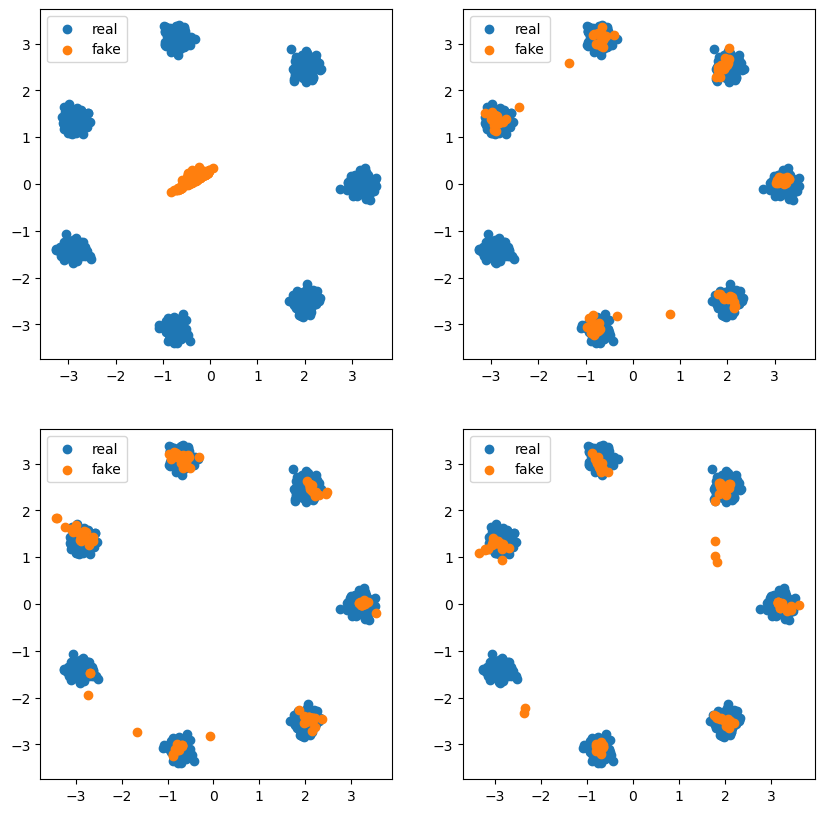

[I 2026-11-04 14:10:50,525] Trial 6 finished with value: 1.7740982942160748 and parameters: {'D_steps': 2, 'lr_ratio': 0.01, 'hidden_ratio': 1, 'G_layers': 1, 'D_layers': 1}. Best is trial 2 with value: 0.002995495493237828.


Мод покрыто: 6


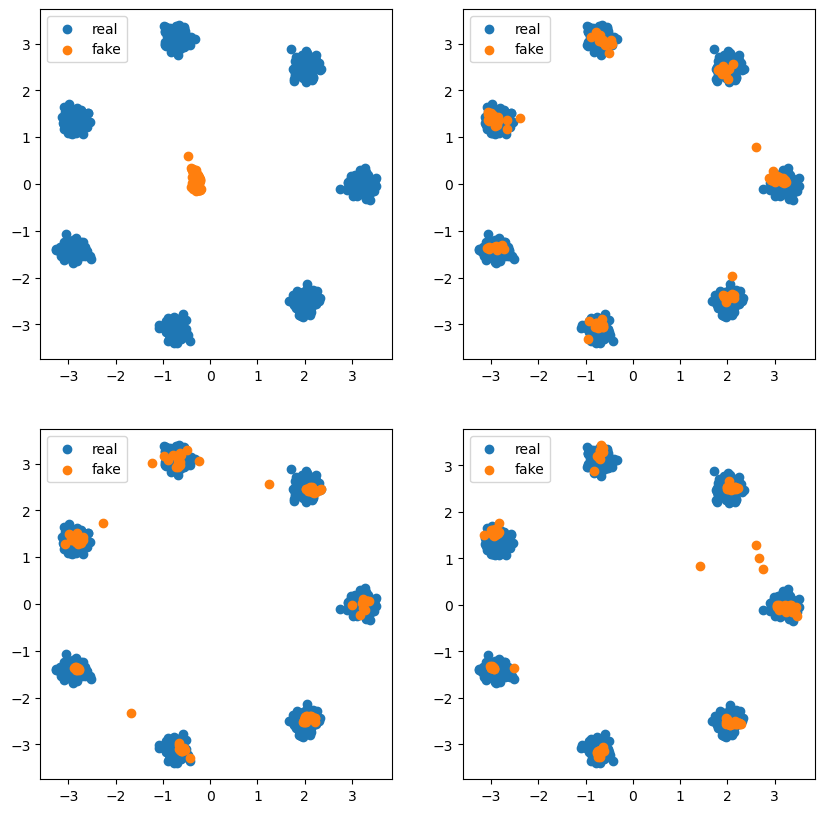

[I 2026-11-04 14:11:28,040] Trial 7 finished with value: 1.9389975214207826 and parameters: {'D_steps': 1, 'lr_ratio': 0.1, 'hidden_ratio': 2, 'G_layers': 1, 'D_layers': 1}. Best is trial 2 with value: 0.002995495493237828.


Мод покрыто: 7


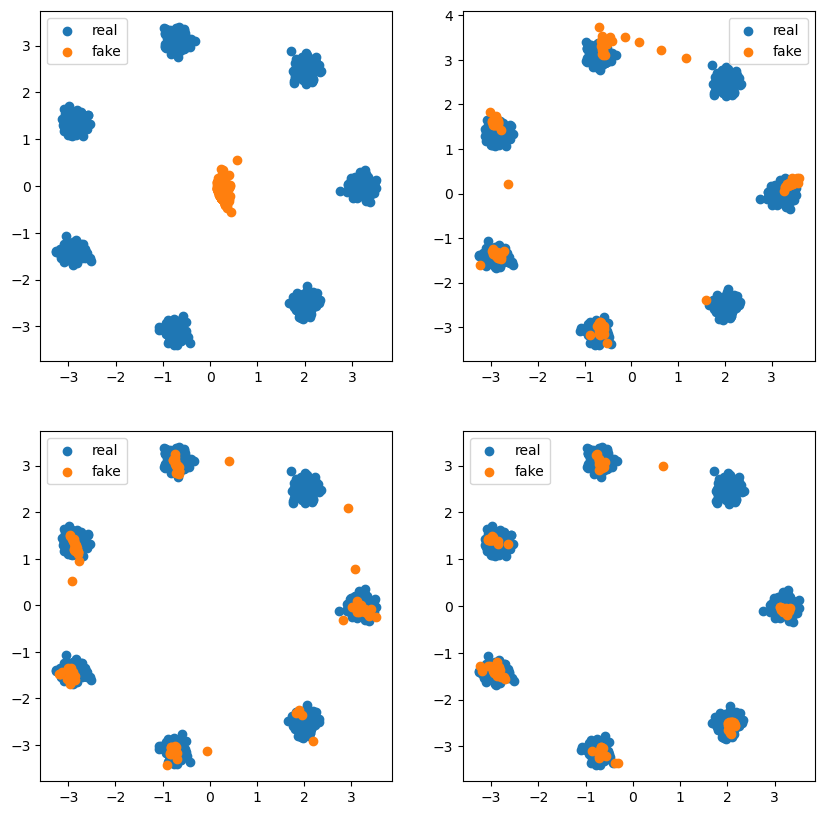

[I 2026-11-04 14:12:04,938] Trial 8 finished with value: 1.7755284955778696 and parameters: {'D_steps': 1, 'lr_ratio': 0.01, 'hidden_ratio': 2, 'G_layers': 1, 'D_layers': 1}. Best is trial 2 with value: 0.002995495493237828.


Мод покрыто: 6


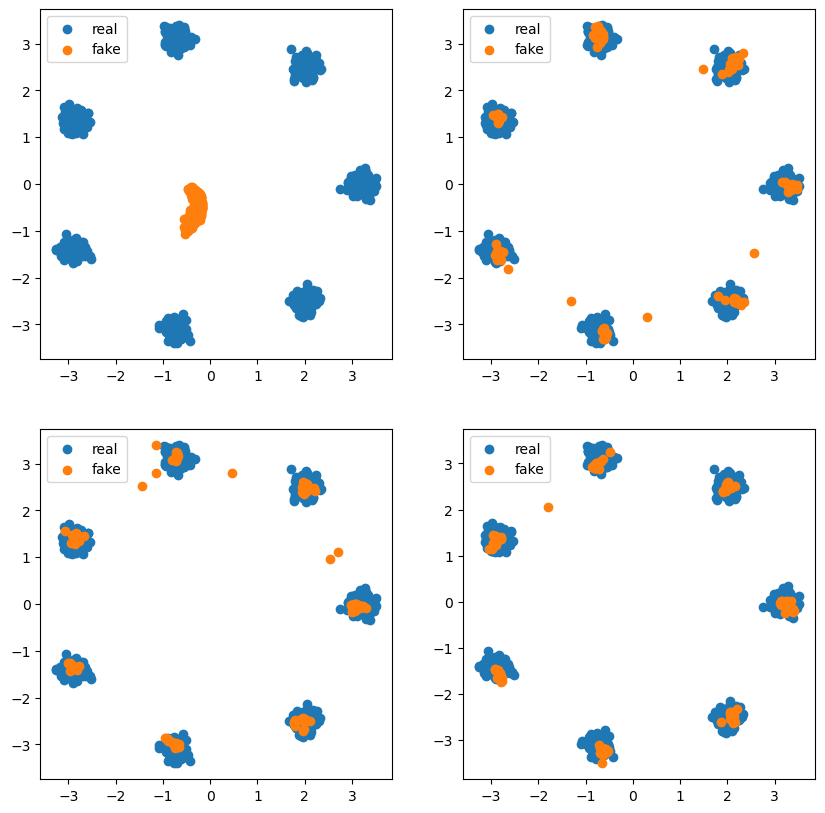

[I 2026-11-04 14:13:07,624] Trial 9 finished with value: 1.929738244156655 and parameters: {'D_steps': 2, 'lr_ratio': 0.01, 'hidden_ratio': 2, 'G_layers': 1, 'D_layers': 1}. Best is trial 2 with value: 0.002995495493237828.


Мод покрыто: 7


In [17]:
study = optuna.create_study(direction='minimize')

study.optimize(objective, n_trials=10)

**Таблица результатов** всех испытаний Optuna: значение метрики и гиперпараметры каждого прогона.

In [24]:
df = study.trials_dataframe()
df.sort_values(['value'])

,number,value,datetime_start,datetime_complete,duration,params_D_layers,params_D_steps,params_G_layers,params_hidden_ratio,params_lr_ratio,state
2,2,0.002995,2026-11-04 14:04:48.028507,2026-11-04 14:06:36.163507,0 days 00:01:48.135000,2,3,1,2,0.01,COMPLETE
1,1,1.595395,2026-11-04 14:03:31.732188,2026-11-04 14:04:48.027717,0 days 00:01:16.295529,2,2,1,2,0.01,COMPLETE
6,6,1.774098,2026-11-04 14:10:04.852143,2026-11-04 14:10:50.525100,0 days 00:00:45.672957,1,2,1,1,0.01,COMPLETE
8,8,1.775528,2026-11-04 14:11:28.041231,2026-11-04 14:12:04.938441,0 days 00:00:36.897210,1,1,1,2,0.01,COMPLETE
5,5,1.779561,2026-11-04 14:09:06.802601,2026-11-04 14:10:04.849247,0 days 00:00:58.046646,1,2,1,2,0.01,COMPLETE
0,0,1.871096,2026-11-04 14:02:31.568922,2026-11-04 14:03:31.731576,0 days 00:01:00.162654,1,2,1,2,0.01,COMPLETE
4,4,1.922448,2026-11-04 14:07:12.317576,2026-11-04 14:09:06.801563,0 days 00:01:54.483987,2,3,1,2,0.10,COMPLETE
9,9,1.929738,2026-11-04 14:12:04.939077,2026-11-04 14:13:07.624495,0 days 00:01:02.685418,1,2,1,2,0.01,COMPLETE
3,3,1.937661,2026-11-04 14:06:36.164927,2026-11-04 14:07:12.316917,0 days 00:00:36.151990,1,1,1,2,0.01,COMPLETE
7,7,1.938998,2026-11-04 14:10:50.525440,2026-11-04 14:11:28.040623,0 days 00:00:37.515183,1,1,1,2,0.10,COMPLETE


In [25]:
study.best_params

{'D_steps': 3,
 'lr_ratio': 0.01,
 'hidden_ratio': 2,
 'G_layers': 1,
 'D_layers': 2}

**График: степень коллапса мод в зависимости от набора гиперпараметров** по испытаниям — наглядно показывает, какие настройки ведут к потере мод.

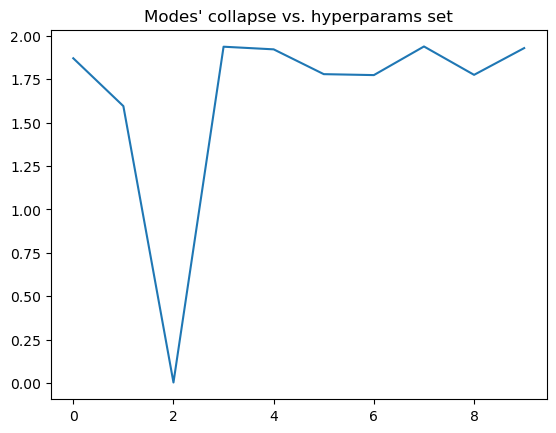

In [26]:
plt.plot(df['number'], df['value'])
plt.title("Modes' collapse vs. hyperparams set")
plt.show()

## Контрольные вопросы к защите лабораторной работы

### 1. В чём различие функций потерь генератора и дискриминатора? Почему их нельзя обучать одним общим шагом градиентного спуска по общей функции потерь?

У генератора и дискриминатора разные цели -- дискриминатор стремится реальным точкам выдавать вероятности 1 и ложным -- нули. А генератор хочет, чтобы дискриминатор на фейки отвечал 1.

### 2. Что такое non-saturating loss генератора и зачем он используется вместо исходной формулы минимакса?

В исходной минимаксной постановке генератор минимизирует log(1 − D(G(z))). Проблема в начале обучения: пока G выдаёт мусор, дискриминатор легко его распознаёт, D(G(z)) ≈ 0, а в этой точке функция log(1 − D(G(z))) почти плоская — её градиент близок к нулю. Генератор получает слабый сигнал именно тогда, когда он хуже всего и учиться нужно сильнее всего (эффект насыщения).

Non-saturating loss решает это заменой цели: вместо минимизации log(1 − D(G(z))) генератор максимизирует log D(G(z)) (эквивалентно минимизации −log D(G(z))). Смысл тот же — заставить дискриминатор принять подделку за настоящую, то есть D(G(z)) → 1, — но форма другая: при D(G(z)) ≈ 0 функция −log D(G(z)) имеет большой градиент, поэтому G получает сильный толчок и быстро улучшается на старте.

Обе формы — частный случай бинарной кросс-энтропии: non-saturating loss это BCE между D(G(z)) и меткой 1 (генератор «выдаёт» свои подделки за реальные данные). Благодаря сильному градиенту на ранних этапах эта версия используется на практике почти всегда.

### 3. Почему дискриминатор в 2D-задаче лучше строить с LeakyReLU, а не с обычнымvReLU?

Главная причина — проблема «мёртвых» нейронов (dying ReLU). Обычный ReLU обнуляет все отрицательные входы, и его производная на отрицательной стороне равна строго нулю. Если нейрон попадает в зону, где он стабильно выдаёт 0, градиент через него перестаёт течь, и он фактически «умирает» — больше не обучается. У дискриминатора это особенно болезненно: именно через него градиент проходит к генератору (G обучается по сигналу от D), поэтому обнулённые градиенты в D тормозят обучение сразу обеих сетей.

LeakyReLU вместо нуля даёт небольшой наклон на отрицательной стороне (например, 0.2·x при x < 0). Производная там не нулевая, а маленькая положительная — градиент продолжает течь даже через «неактивные» нейроны, и они не умирают. Сеть сохраняет полноту градиентного сигнала.

### 4. Как по кривым LD и LG (в отличие от обычной сети с одной функцией потерь) судить о том, обучение сходится или нет?

В отличие от обычной сети с одной функцией потерь, при обучении GAN обе кривые
потерь (LD и LG) не обязаны монотонно убывать – при успешном обучении они, как
правило, колеблются вокруг некоторого уровня (что отражает динамическое равновесие
двух конкурирующих сетей), и по одной только кривой потерь часто нельзя надёжно
судить о качестве генерации. Поэтому для 2D-задачи основной инструмент диагностики –
визуализация: облако сгенерированных точек, наложенное на облако реальных точек,
на нескольких эпохах обучения.

### 5. Что такое коллапс мод и как его продемонстрировать на многомодальном 2D-распределении? Какие гиперпараметры способны его спровоцировать?

Особенно наглядно на 2D-данных с несколькими модами (например, смесь нескольких гауссиан) проявляется коллапс мод (mode collapse): генератор вместо покрытия
всех мод целевого распределения «схлопывается» в одну или несколько мод, продолжая
при этом уверенно обманывать текущий дискриминатор. Численно коллапс мод можно
диагностировать, разбив сгенерированные точки по ближайшей моде целевого распределения и посчитав, сколько мод из общего числа получили заметную (например, ≥ 1%)
долю сгенерированных точек.

### 6. Почему при вычислении LD используется x_fake.detach(), а при вычислении LG – нет?

Проблема без detach: когда посчитаешь лосс D и вызовешь backward(), градиент пойдёт через fake внутрь генератора и зацепит его параметры. А на шаге D генератор трогать нельзя — мы сейчас учим только дискриминатор. Получилось бы, что обучение D заодно портит G.

detach() обрезает эту связь: fake подаётся в D просто как готовые числа, «вот тебе картинки, скажи — настоящие или нет». Градиент дойдёт только до параметров D и остановится на границе, в G не полезет. Когда учим G, всё наоборот — градиент обязан дойти до генератора, иначе он не обновится